<a href="https://colab.research.google.com/github/yanapatt/MarisaNeXt/blob/main/data/Preparing_MushroomB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Preparing Dataset**
---
Dataset: Mashroom_Image_Classification (MushroomB)  
มีจำนวนทั้งหมด 16 Classes

Step

1.   Upload zip file dataset จาก Google Drive มาไว้บน Runtime Directory
2.   `Rename folder ใน runtime directory จาก _RAW ให้เป็น _CLEAN`
3.   ทำ Section 2 ให้ถึง Export bad images ก่อน แล้วไป Recheck image ใน Google Drive
4.   List รายชื่อไฟล์ที่จะลบแบบ csv ไฟล์ ตั้งชื่อไฟล์ให้ลงท้ายด้วย _TO_DELETE
5.   เริ่มกระบวนการ 1 ใหม่ หลังจากมี _TO_DELETE แล้ว (ให้ Visualization Image ก่อนลบภาพไม่งั้นจะ Error ถ้าอยากจะแสดงภาพที่ลบออกไปแล้ว และเสียเวลา Load ไฟล์มาใหม่)



In [ ]:
%%capture
!pip install imagededup

In [ ]:
import os
import shutil
import zipfile
import json
import pickle

import numpy as np
import pandas as pd
import random as rd
from sklearn.model_selection import train_test_split

## **Section 1: Setting directory**

### **Drive directory**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
drive_dir = '/content/drive/MyDrive/projectMushroom'
data_name = 'MushroomB'
drive_data_dir = f'{drive_dir}/data/{data_name}'
bad_data_dir = f'{drive_data_dir}/imagesQuarantine'
font_dir = f'{drive_dir}/assets/fonts'

os.makedirs(bad_data_dir, exist_ok=True)
os.chdir(drive_dir)
print(f'Current directory: {os.getcwd()}')

Current directory: /content/drive/MyDrive/projectMushroom


In [ ]:
import src.reproducibility as reproducibility
import src.buildDirectory as buildDirectory
import src.preprocessing as preprocessing
import src.visualization as visualization

visualization.matplotlib_font(font_dir=font_dir, prefer_name='Times-Roman')

'OPTITimes-Roman'

### **Runtime directory**

In [ ]:
SEED = 42
reproducibility.global_seed(seed=SEED)

Global Seed set to: 42


In [ ]:
runtime_dir = '/content'
runtime_data_dir = f'{runtime_dir}/data'
runtime_datasplit_dir = f'{runtime_data_dir}/{data_name}_SPLIT'
runtime_dataclean_dir = f'{runtime_data_dir}/{data_name}_CLEAN'

os.makedirs(runtime_data_dir, exist_ok=True)
os.makedirs(runtime_datasplit_dir, exist_ok=True)
os.makedirs(runtime_dataclean_dir, exist_ok=True)

In [ ]:
with zipfile.ZipFile(f'{drive_data_dir}/{data_name}_RAW.zip', 'r') as zip_ref:
    zip_ref.extractall(runtime_data_dir)
print(f'Dataset has been extracted to {runtime_data_dir}')

Dataset has been extracted to /content/data


## **Section 2: Verify images**

### **Check basic images component**

In [ ]:
verify_report = preprocessing.verify_images(
    data_dir=runtime_data_dir,
    check_solid=True
)

[Log]: Extensions detect .jpg
[Log]: Total images found: 3017


Verifying images: 100%|██████████| 3017/3017 [01:00<00:00, 49.57it/s]


--- Summary ---
Total issues found: 0


In [ ]:
verify_report_df = pd.DataFrame(verify_report)
verify_report_df.to_csv(f'{bad_data_dir}/{data_name}_VERIFY.csv', index=False)

### **Check outlier on dataset**

In [ ]:
outlier_report = preprocessing.find_outliers(
    data_dir=runtime_data_dir,
    seed=SEED,
    contamination=0.05
)

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 88.2MB/s]
2026-02-26 02:54:34,564: INFO Device set to cpu ..
INFO:imagededup.methods.cnn:Device set to cpu ..
2026-02-26 02:54:34,569: INFO Initialized: mobilenet_v3_small for feature extraction ..
INFO:imagededup.methods.cnn:Initialized: mobilenet_v3_small for feature extraction ..
2026-02-26 02:54:34,575: INFO Start: Image encoding generation
INFO:imagededup.methods.cnn:Start: Image encoding generation


Found 16 folders containing images.


2026-02-26 02:54:43,209: INFO End: Image encoding generation
INFO:imagededup.methods.cnn:End: Image encoding generation
2026-02-26 02:54:43,699: INFO Start: Image encoding generation
INFO:imagededup.methods.cnn:Start: Image encoding generation


Class Phallus_Impudicus-NotEdible: Found 11 candidate outlier.


2026-02-26 02:54:56,019: INFO End: Image encoding generation
INFO:imagededup.methods.cnn:End: Image encoding generation
2026-02-26 02:54:56,747: INFO Start: Image encoding generation
INFO:imagededup.methods.cnn:Start: Image encoding generation


... (25 outputs left out)

2026-02-26 02:56:33,433: INFO End: Image encoding generation
INFO:imagededup.methods.cnn:End: Image encoding generation
2026-02-26 02:56:33,917: INFO Start: Image encoding generation
INFO:imagededup.methods.cnn:Start: Image encoding generation


Class Morchella_Deliciosa-Edible: Found 13 candidate outlier.


2026-02-26 02:56:39,193: INFO End: Image encoding generation
INFO:imagededup.methods.cnn:End: Image encoding generation


Class Clitocybe_Costata-Edible: Found 7 candidate outlier.


In [ ]:
outlier_report_df = pd.DataFrame(outlier_report)
outlier_report_df.to_csv(f'{bad_data_dir}/{data_name}_OUTLIER.csv', index=False)

### **Check duplicates images**

In [ ]:
hashes_dict = preprocessing.find_hasher(data_dir=runtime_data_dir, output_path=f'{bad_data_dir}/{data_name}_HASHES.pkl')

2026-02-26 02:56:46,823: INFO Start: Calculating hashes...
INFO:imagededup.methods.hashing:Start: Calculating hashes...


Found 16 folders containing images.


100%|██████████| 219/219 [00:05<00:00, 41.36it/s]
2026-02-26 02:56:52,261: INFO End: Calculating hashes!
INFO:imagededup.methods.hashing:End: Calculating hashes!
2026-02-26 02:56:52,267: INFO Start: Calculating hashes...
INFO:imagededup.methods.hashing:Start: Calculating hashes...
100%|██████████| 310/310 [00:08<00:00, 37.89it/s]
2026-02-26 02:57:00,569: INFO End: Calculating hashes!
INFO:imagededup.methods.hashing:End: Calculating hashes!
2026-02-26 02:57:00,575: INFO Start: Calculating hashes...
INFO:imagededup.methods.hashing:Start: Calculating hashes...
100%|██████████| 226/226 [00:05<00:00, 44.61it/s]
2026-02-26 02:57:05,785: INFO End: Calculating hashes!
INFO:imagededup.methods.hashing:End: Calculating hashes!
2026-02-26 02:57:05,793: INFO Start: Calculating hashes...
INFO:imagededup.methods.hashing:Start: Calculating hashes...
100%|██████████| 128/128 [00:05<00:00, 24.32it/s]
2026-02-26 02:57:11,163: INFO End: Calculating hashes!
INFO:imagededup.methods.hashing:End: Calculating 

Saved hashes for 16 unique classes to /content/drive/MyDrive/projectMushroom/data/MushroomB/imagesQuarantine/MushroomB_HASHES.pkl


In [ ]:
with open(f'{bad_data_dir}/{data_name}_HASHES.pkl', 'rb') as f:
    hashes_dict = pickle.load(f)

intra_report, inter_report = preprocessing.find_duplicates(hashes_dict=hashes_dict)

Processing Classes: 100%|██████████| 16/16 [00:00<00:00, 7064.83it/s]


Found 3017 images in total.


In [ ]:
intra_report_df = pd.DataFrame(intra_report)
intra_report_df.to_csv(f'{bad_data_dir}/{data_name}_INTRA_DUPLICATES.csv', index=False)

inter_report_df = pd.DataFrame(inter_report)
inter_report_df.to_csv(f'{bad_data_dir}/{data_name}_INTER_DUPLICATES.csv', index=False)

### **Export bad images to G-Drive**

In [ ]:
verify_report_df = pd.read_csv(f'{bad_data_dir}/{data_name}_VERIFY.csv')
outlier_report_df = pd.read_csv(f'{bad_data_dir}/{data_name}_OUTLIER.csv')
intra_report_df = pd.read_csv(f'{bad_data_dir}/{data_name}_INTRA_DUPLICATES.csv')
inter_report_df = pd.read_csv(f'{bad_data_dir}/{data_name}_INTER_DUPLICATES.csv')

In [ ]:
buildDirectory.export_bad_images(
    df=verify_report_df,
    filepaths_col='filepaths',
    filename_col='filename',
    label_col='label',
    issue_col='issue',
    output_base_dir=bad_data_dir
)

Exporting: 0it [00:00, ?it/s]


Export completed to: /content/drive/MyDrive/projectMushroom/data/MushroomB/imagesQuarantine


In [ ]:
buildDirectory.export_bad_images(
    df=outlier_report_df,
    filepaths_col='filepaths',
    filename_col='filename',
    label_col='label',
    issue_col='issue',
    output_base_dir=bad_data_dir
)

Exporting: 100%|██████████| 158/158 [00:02<00:00, 55.46it/s]


Export completed to: /content/drive/MyDrive/projectMushroom/data/MushroomB/imagesQuarantine


In [ ]:
buildDirectory.export_duplicates_images(
    df=intra_report_df,
    filepaths_col='filepaths',
    filename_col='filename',
    label_col='label',
    hash_group_col='hash_group',
    output_base_dir=bad_data_dir,
    issue_type='intra'
)

Exporting intra: 100%|██████████| 36/36 [00:00<00:00, 54.81it/s]


Export completed to: /content/drive/MyDrive/projectMushroom/data/MushroomB/imagesQuarantine


In [ ]:
buildDirectory.export_duplicates_images(
    df=inter_report_df,
    filepaths_col='filepaths',
    filename_col='filename',
    label_col='label',
    hash_group_col='hash_group',
    output_base_dir=bad_data_dir,
    issue_type='inter'
)

Exporting inter: 0it [00:00, ?it/s]


Export completed to: /content/drive/MyDrive/projectMushroom/data/MushroomB/imagesQuarantine


### **Remove target bad images**

In [ ]:
to_delete_df = pd.read_csv(f'{bad_data_dir}/{data_name}_TO_DELETE.csv')

In [ ]:
for idx, row in to_delete_df.iterrows():
    os.remove(row['filepaths'])

### **Export data after cleaning**

In [ ]:
shutil.make_archive(f'{drive_data_dir}/{data_name}_CLEAN', 'zip', f'{runtime_data_dir}/{data_name}_CLEAN')

'/content/drive/MyDrive/projectMushroom/data/MushroomB/MushroomB_CLEAN.zip'

## **Section 3: Split Dataset**

In [ ]:
with zipfile.ZipFile(f'{drive_data_dir}/{data_name}_CLEAN.zip', 'r') as zip_ref:
    zip_ref.extractall(runtime_dataclean_dir)
print(f'Dataset has been extracted to {runtime_dataclean_dir}')

Dataset has been extracted to /content/data


In [ ]:
filepaths, labels = buildDirectory.read_images(data_dir=f'{runtime_data_dir}/{data_name}_CLEAN')
metadata = pd.DataFrame({
    'filepaths': filepaths,
    'labels': labels
})

In [ ]:
print(f'Total images: {len(metadata)}')
print(f'Unique class: {len(metadata["labels"].unique())}')

Total images: 2999
Unique class: 16


In [ ]:
TEST_SIZE = 0.2

# 100 * 0.2 => 80:20
X_remain, X_test, y_remain, y_test = train_test_split(
    metadata['filepaths'],
    metadata['labels'],
    test_size=TEST_SIZE,
    random_state=SEED,
    stratify=metadata['labels']
)

print('--- Summary ---')
print(f'Total remain images: {len(X_remain)}')
print(f'Total test images: {len(X_test)}')
print(f'Unique class on remain set: {len(y_remain.unique())}')
print(f'Unique class on test set: {len(y_test.unique())}')

--- Summary ---
Total remain images: 2399
Total test images: 600
Unique class on remain set: 16
Unique class on test set: 16


In [ ]:
remain_dir = os.path.join(f'{runtime_datasplit_dir}', 'remain')
test_dir = os.path.join(f'{runtime_datasplit_dir}', 'test')

buildDirectory.to_directory(X_remain, y_remain, remain_dir)
buildDirectory.to_directory(X_test, y_test, test_dir)

Copying to test: 100%|██████████| 600/600 [00:01<00:00, 316.19it/s]


### **Export data after spliting**

In [ ]:
metadata.to_csv(f'{drive_data_dir}/metadata.csv', index=False)
label_names = sorted(metadata['labels'].unique())

In [ ]:
summary_df = pd.DataFrame({
    'Remain (80 %)': [len(os.listdir(f'{remain_dir}/{label}')) for label in label_names],
    'Test (20 %)': [len(os.listdir(f'{test_dir}/{label}')) for label in label_names],
    'Total': [len(os.listdir(f'{remain_dir}/{label}')) + len(os.listdir(f'{test_dir}/{label}')) for label in label_names]
})

summary_df.insert(0, 'Labels', label_names)
summary_df.to_csv(f'{drive_data_dir}/summary.csv', index=False)
summary_df

,Labels,Remain (80 %),Test (20 %),Total
0,Amanita_Caesarea-Edible,182,46,228
1,Amanita_Citrina-Edible,141,35,176
2,Amanita_Pantherina-NotEdible,264,66,330
3,Boletus_Regius-Edible,103,26,129
4,Clitocybe_Costata-Edible,107,27,134
5,Entoloma_Lividum-NotEdible,101,25,126
6,Gyromitra_Esculenta-NotEdible,181,45,226
7,Helvella_Crispa-Edible,247,62,309
8,Hydnum_Rufescens-NotEdible,125,31,156
9,Hygrophorus_Latitabundus-Edible,102,26,128


In [ ]:
shutil.make_archive(f'{drive_data_dir}/{data_name}_SPLIT', 'zip', f'{runtime_datasplit_dir}')

'/content/drive/MyDrive/projectMushroom/data/MushroomB/MushroomB_SPLIT.zip'

## **Section 4: Visualize the images**

### **Candidate Outlier Images**

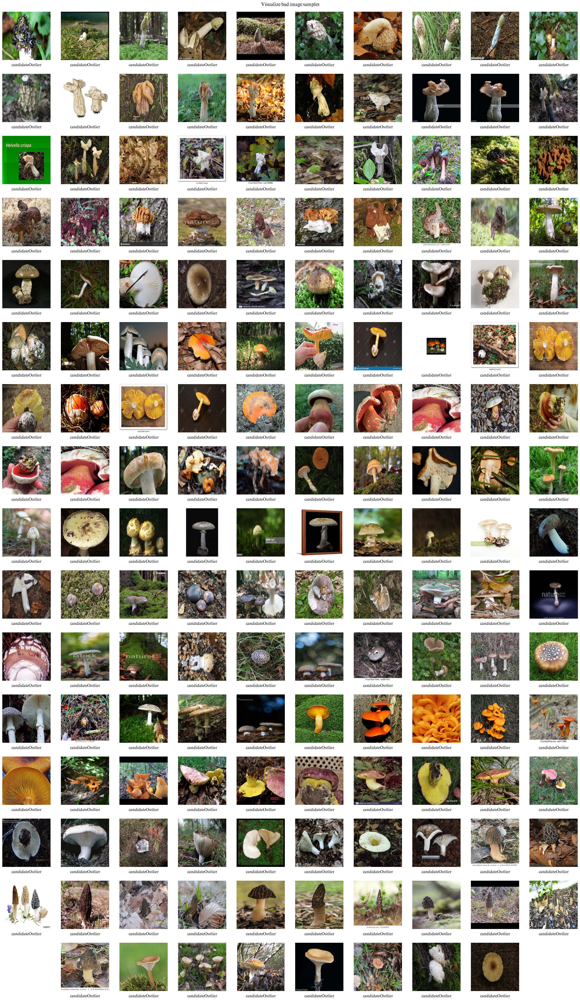

In [ ]:
visualization.vis_images(
    df=outlier_report_df,
    filepaths_col='filepaths',
    label_col='issue',
    n_rows=16,
    n_cols=10,
    title='Visualize bad image samples',
    fontsize=12
)

### **Intra duplicates**

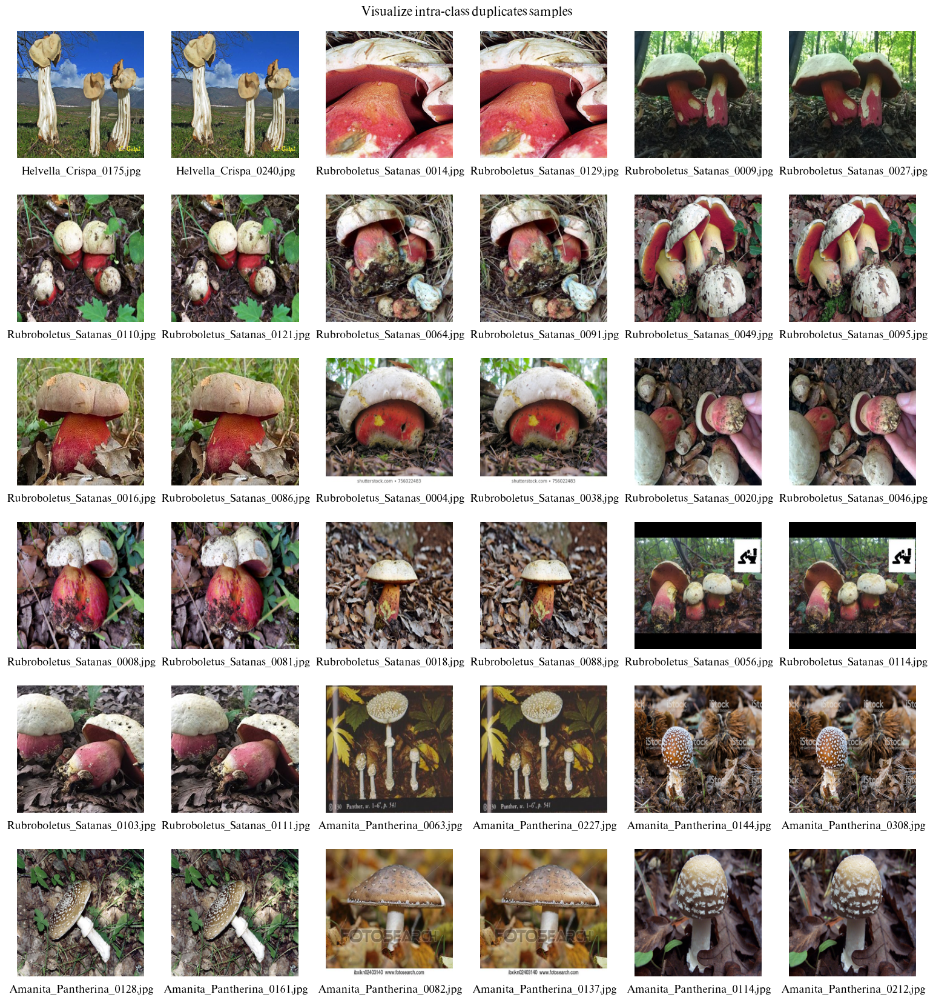

In [ ]:
visualization.vis_images(
    df=intra_report_df,
    filepaths_col='filepaths',
    label_col='filename',
    n_rows=6,
    n_cols=6,
    title='Visualize intra-class duplicates samples',
    fontsize=12
)

### **Inter duplicates**

In [ ]:
'''helperFunctions.vis_images(
    df=inter_report_df,
    filepaths_col='filepaths',
    label_col='filename',
    n_rows=1,
    n_cols=4,
    title='Visualize inter-class duplicates samples',
    fontsize=12
)'''

### **Dataset by class**

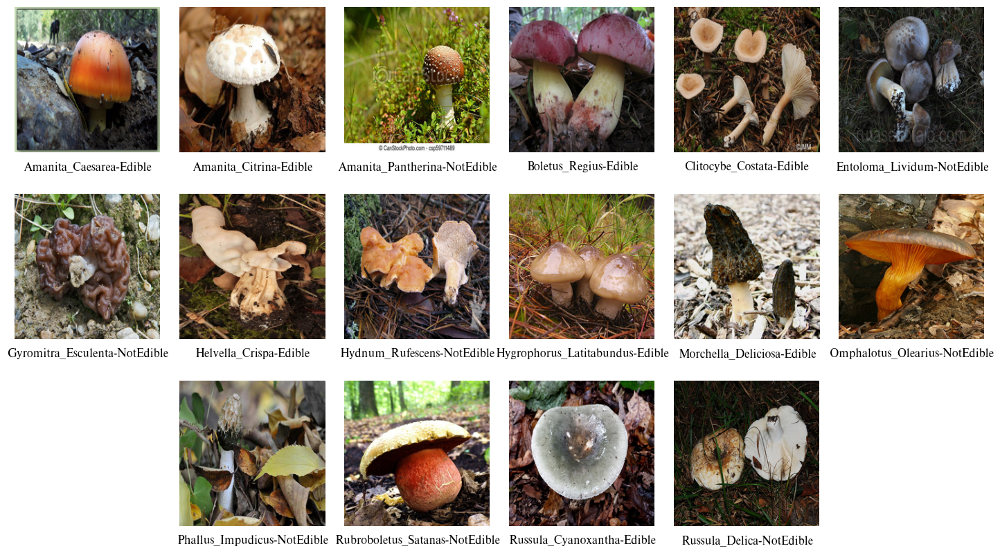

In [ ]:
unique_label = (
    metadata.groupby('labels', as_index=False).sample(n=1, random_state=234)
)

visualization.vis_images(
    df=unique_label,
    filepaths_col='filepaths',
    label_col='labels',
    n_rows=3,
    n_cols=6,
    target_size=(224, 224),
    figsize=(14, 6),
    fontsize=11,
    title=None,
    save_path=f'{drive_data_dir}/dataset_overview'
)

## **Section 5: Extra (Addition)**

### **Dataset Description**

In [ ]:
raw_metadata = pd.read_csv(f'{drive_data_dir}/raw_metadata.csv')
metadata = pd.read_csv(f'{drive_data_dir}/metadata.csv')
summary = pd.read_csv(f'{drive_data_dir}/summary.csv')

verify_report_df = pd.read_csv(f'{bad_data_dir}/{data_name}_VERIFY.csv')
outlier_report_df = pd.read_csv(f'{bad_data_dir}/{data_name}_OUTLIER.csv')
intra_report_df = pd.read_csv(f'{bad_data_dir}/{data_name}_INTRA_DUPLICATES.csv')
inter_report_df = pd.read_csv(f'{bad_data_dir}/{data_name}_INTER_DUPLICATES.csv')
to_delete_df = pd.read_csv(f'{bad_data_dir}/{data_name}_TO_DELETE.csv')

In [ ]:
raw_metadata = raw_metadata.sort_values(by='labels')
all_classes = raw_metadata['labels'].unique().tolist()

In [ ]:
summary_issue = pd.crosstab(
    to_delete_df['label'],
    to_delete_df['issue'],
    rownames=['Labels'],
    colnames=['IssueType']
)

all_possible_issues = ['candidateOutlier', 'corrupted', 'intraDuplicate', 'interDuplicate', 'solidColor']
summary_issue = summary_issue.reindex(index=all_classes, columns=all_possible_issues).fillna(0).astype(int)

summary_issue['Outlier'] = summary_issue['candidateOutlier']
summary_issue['Corrupted'] = summary_issue['corrupted'] + summary_issue['solidColor']
summary_issue['Duplicate'] = summary_issue['intraDuplicate'] + summary_issue['interDuplicate']

final_cols = ['Outlier', 'Corrupted', 'Duplicate']
summary_issue = summary_issue[final_cols].copy()
summary_issue['Count'] = summary_issue.sum(axis=1)

summary_issue = summary_issue.sort_index()

In [ ]:
summary = summary.rename(columns={'Total': 'Final Count'})

In [ ]:
raw_count_df = raw_metadata['labels'].value_counts().reset_index()
raw_count_df.columns = ['Labels', 'Initial Count']
raw_count_df = raw_count_df.sort_values(by='Labels').reset_index(drop=True)

In [ ]:
merged_1 = pd.merge(raw_count_df, summary, on='Labels')
column_order = ['Labels', 'Initial Count', 'Final Count', 'Remain (80 %)', 'Test (20 %)']
merged_1 = merged_1[column_order]

In [ ]:
def format_scientific_name(name):
    parts = name.split(' ')
    if len(parts) > 1:
        return parts[0] + ' ' + ' '.join([p.lower() for p in parts[1:]])
    return name

merged_2 = pd.merge(merged_1, summary_issue, on='Labels')
merged_2['Type'] = merged_2['Labels'].apply(lambda x: 'Edible' if 'Edible' in x and 'NotEdible' not in x else 'Not Edible')

merged_2['Labels'] = merged_2['Labels'].str.replace('_', ' ', regex=False)
merged_2['Labels'] = merged_2['Labels'].str.replace('-Edible', '', regex=False)
merged_2['Labels'] = merged_2['Labels'].str.replace('-NotEdible', '', regex=False)
merged_2['Labels'] = merged_2['Labels'].apply(format_scientific_name)

merged_2 = merged_2.sort_values(by=['Type', 'Labels'], ascending=[True, True])

edible_top8 = merged_2[merged_2['Type'] == 'Edible'].head(8)
not_edible_top8 = merged_2[merged_2['Type'] == 'Not Edible'].head(8)

merged_2 = pd.concat([edible_top8, not_edible_top8]).reset_index(drop=True)
re_order = ['Type', 'Labels', 'Initial Count', 'Corrupted', 'Duplicate', 'Outlier', 'Count', 'Final Count', 'Remain (80 %)', 'Test (20 %)']
merged_2 = merged_2[re_order]
merged_2.to_csv(f'{drive_data_dir}/summary_desc.csv', index=False)
merged_2

,Type,Labels,Initial Count,Corrupted,Duplicate,Outlier,Count,Final Count,Remain (80 %),Test (20 %)
0,Edible,Amanita caesarea,228,0,0,0,0,228,182,46
1,Edible,Amanita citrina,176,0,0,0,0,176,141,35
2,Edible,Boletus regius,129,0,0,0,0,129,103,26
3,Edible,Clitocybe costata,134,0,0,0,0,134,107,27
4,Edible,Helvella crispa,310,0,1,0,1,309,247,62
5,Edible,Hygrophorus latitabundus,128,0,0,0,0,128,102,26
6,Edible,Morchella deliciosa,245,0,0,0,0,245,196,49
7,Edible,Russula cyanoxantha,179,0,0,0,0,179,143,36
8,Not Edible,Amanita pantherina,335,0,5,0,5,330,264,66
9,Not Edible,Entoloma lividum,126,0,0,0,0,126,101,25
